In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("环境配置成功！")
print("NumPy版本：", np.__version__)
print("Pandas版本：", pd.__version__)
print("Scikit-learn版本：", sklearn.__version__)

环境配置成功！
NumPy版本： 2.4.6
Pandas版本： 3.0.5
Scikit-learn版本： 1.9.0


In [6]:
import sys
print(sys.executable)

D:\aaaa\anaconda\envs\cmapss\python.exe


In [7]:
train_path = "../data/FD001/train_FD001.txt"

In [8]:
train_df = pd.read_csv(
    train_path,
    sep=r"\s+",
    header=None
)

train_df.head()

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [9]:
print("数据形状：", train_df.shape)

数据形状： (20631, 26)


In [10]:
column_names = (
    ["unit", "cycle"]
    + ["op_setting_1", "op_setting_2", "op_setting_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train_df.columns = column_names

In [11]:
train_df.head()

,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [12]:
engine_life = train_df.groupby("unit")["cycle"].max()

engine_life.head()

unit
1    192
2    287
3    179
4    189
5    269
Name: cycle, dtype: int64

In [13]:
engine_life.describe()

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

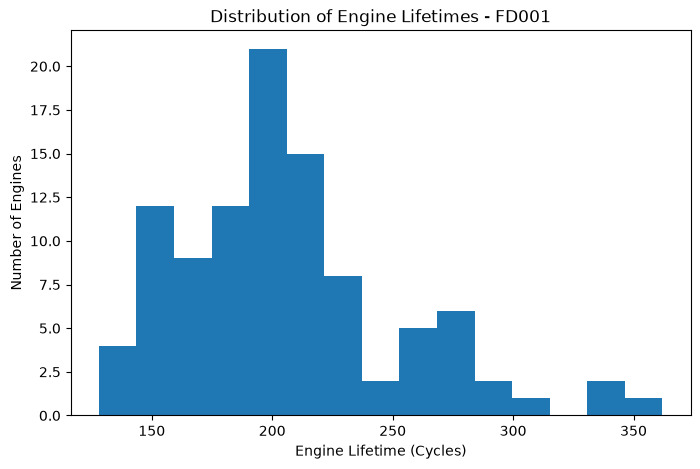

In [14]:
plt.figure(figsize=(8, 5))
plt.hist(engine_life, bins=15)

plt.xlabel("Engine Lifetime (Cycles)")
plt.ylabel("Number of Engines")
plt.title("Distribution of Engine Lifetimes - FD001")

plt.show()

In [15]:
engine_1 = train_df[train_df["unit"] == 1]

print("第1台发动机数据行数：", len(engine_1))
print("第1台发动机最大周期：", engine_1["cycle"].max())

第1台发动机数据行数： 192
第1台发动机最大周期： 192


In [16]:
engine_life.describe()

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

In [17]:
train_df["max_cycle"] = train_df.groupby("unit")["cycle"].transform("max")

train_df[["unit", "cycle", "max_cycle"]].head(10)

,unit,cycle,max_cycle
0,1,1,192
1,1,2,192
2,1,3,192
3,1,4,192
4,1,5,192
5,1,6,192
6,1,7,192
7,1,8,192
8,1,9,192
9,1,10,192


In [18]:
train_df["RUL"] = train_df["max_cycle"] - train_df["cycle"]

train_df[["unit", "cycle", "max_cycle", "RUL"]].head(10)

,unit,cycle,max_cycle,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


In [19]:
train_df[train_df["unit"] == 1][
    ["unit", "cycle", "max_cycle", "RUL"]
].tail(10)

,unit,cycle,max_cycle,RUL
182,1,183,192,9
183,1,184,192,8
184,1,185,192,7
185,1,186,192,6
186,1,187,192,5
187,1,188,192,4
188,1,189,192,3
189,1,190,192,2
190,1,191,192,1
191,1,192,192,0


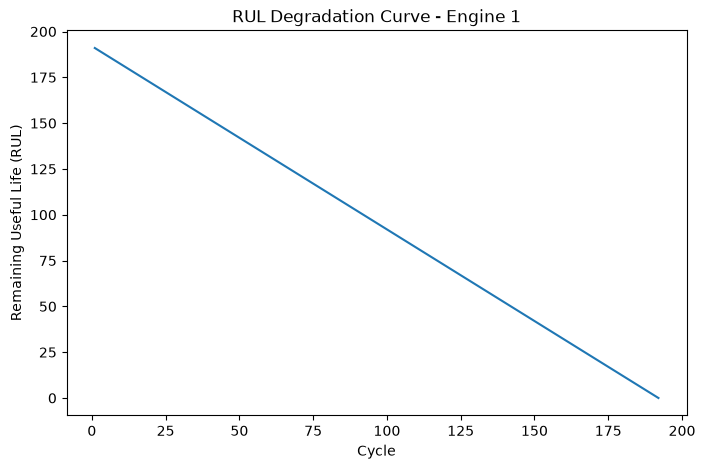

In [20]:
engine_1 = train_df[train_df["unit"] == 1]

plt.figure(figsize=(8, 5))

plt.plot(engine_1["cycle"], engine_1["RUL"])

plt.xlabel("Cycle")
plt.ylabel("Remaining Useful Life (RUL)")
plt.title("RUL Degradation Curve - Engine 1")

plt.show()

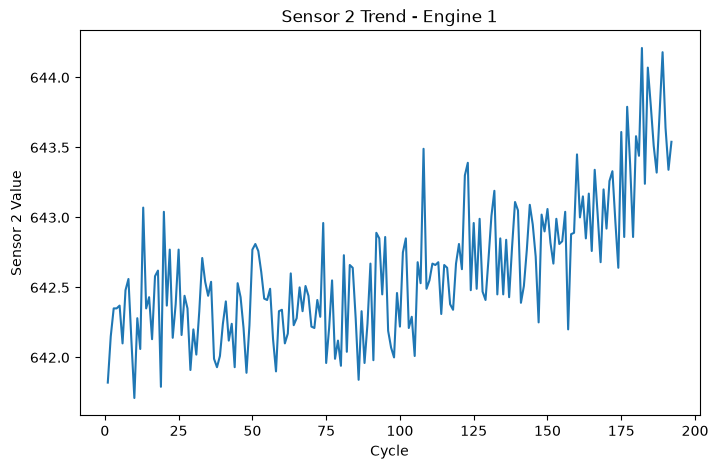

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(engine_1["cycle"], engine_1["sensor_2"])

plt.xlabel("Cycle")
plt.ylabel("Sensor 2 Value")
plt.title("Sensor 2 Trend - Engine 1")

plt.show()

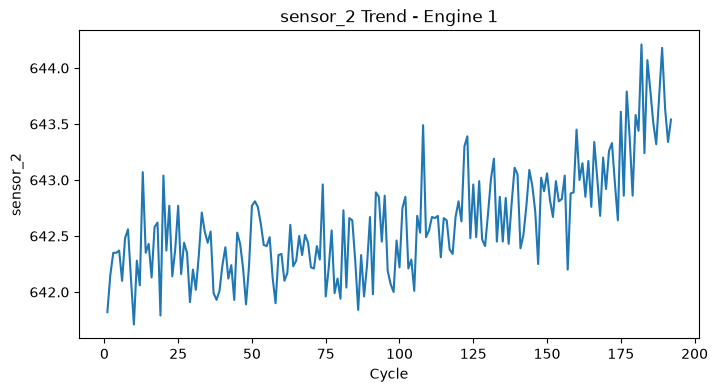

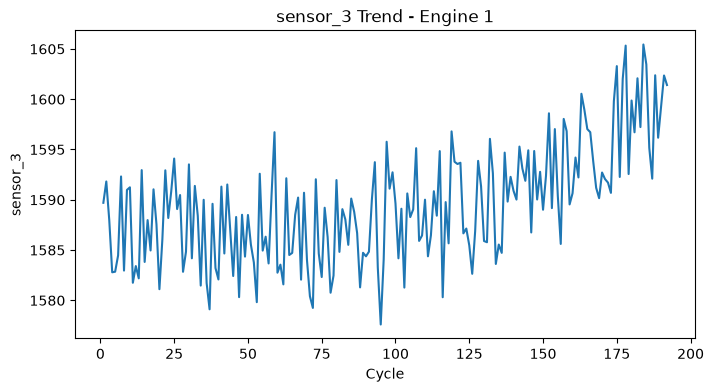

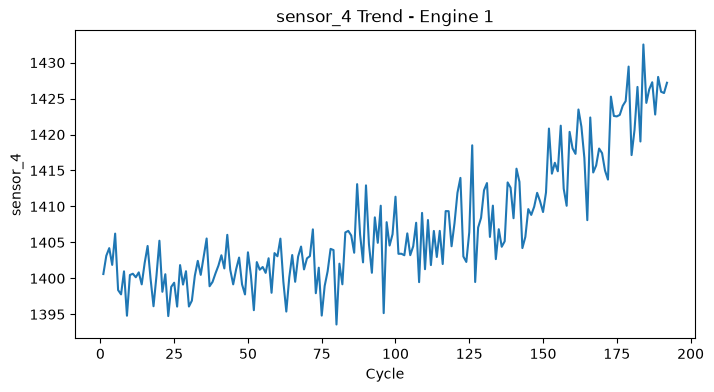

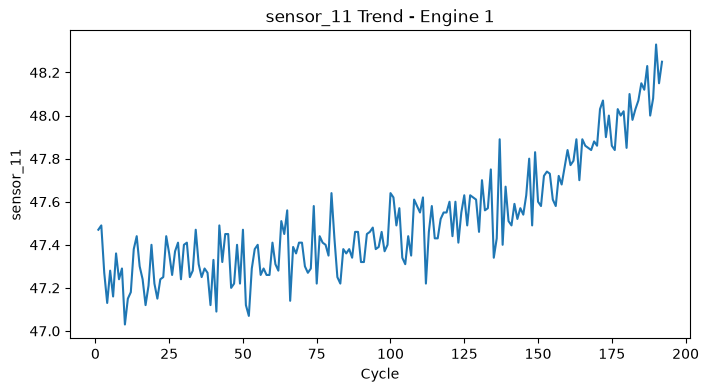

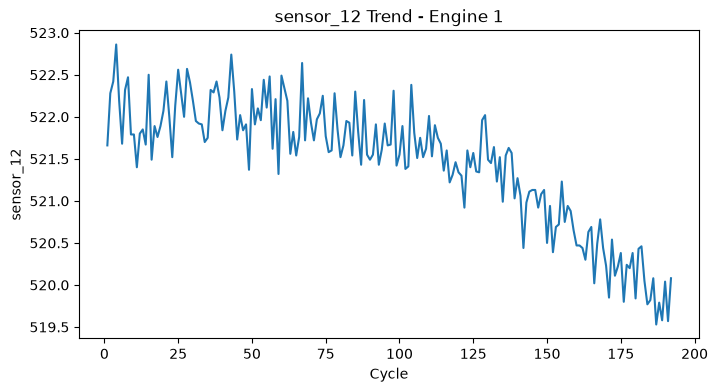

In [22]:
sensors_to_plot = ["sensor_2", "sensor_3", "sensor_4", "sensor_11", "sensor_12"]

for sensor in sensors_to_plot:
    plt.figure(figsize=(8, 4))
    plt.plot(engine_1["cycle"], engine_1[sensor])
    plt.xlabel("Cycle")
    plt.ylabel(sensor)
    plt.title(f"{sensor} Trend - Engine 1")
    plt.show()

In [23]:
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

sensor_std = train_df[sensor_cols].std().sort_values()

sensor_std

sensor_1     0.000000e+00
sensor_10    0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    3.469531e-18
sensor_5     5.329200e-15
sensor_6     1.388985e-03
sensor_15    3.750504e-02
sensor_8     7.098548e-02
sensor_13    7.191892e-02
sensor_21    1.082509e-01
sensor_20    1.807464e-01
sensor_11    2.670874e-01
sensor_2     5.000533e-01
sensor_12    7.375534e-01
sensor_7     8.850923e-01
sensor_17    1.548763e+00
sensor_3     6.131150e+00
sensor_4     9.000605e+00
sensor_14    1.907618e+01
sensor_9     2.208288e+01
dtype: float64

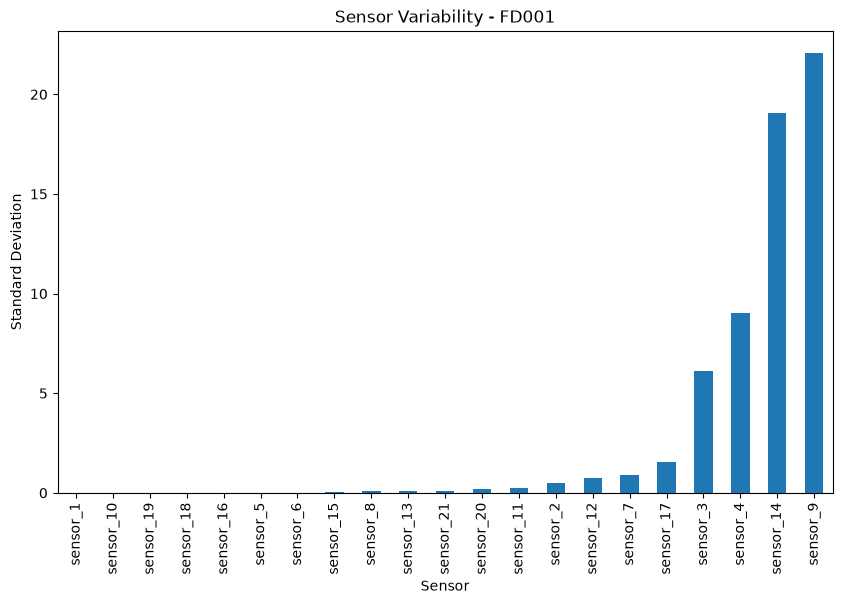

In [24]:
plt.figure(figsize=(10, 6))

sensor_std.plot(kind="bar")

plt.xlabel("Sensor")
plt.ylabel("Standard Deviation")
plt.title("Sensor Variability - FD001")

plt.show()

In [25]:
sensor_corr = train_df[sensor_cols + ["RUL"]].corr()["RUL"].drop("RUL")

sensor_corr = sensor_corr.sort_values()

sensor_corr

sensor_11   -0.696228
sensor_4    -0.678948
sensor_15   -0.642667
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
sensor_20    0.629428
sensor_21    0.635662
sensor_7     0.657223
sensor_12    0.671983
sensor_1          NaN
sensor_5          NaN
sensor_10         NaN
sensor_16         NaN
sensor_18         NaN
sensor_19         NaN
Name: RUL, dtype: float64

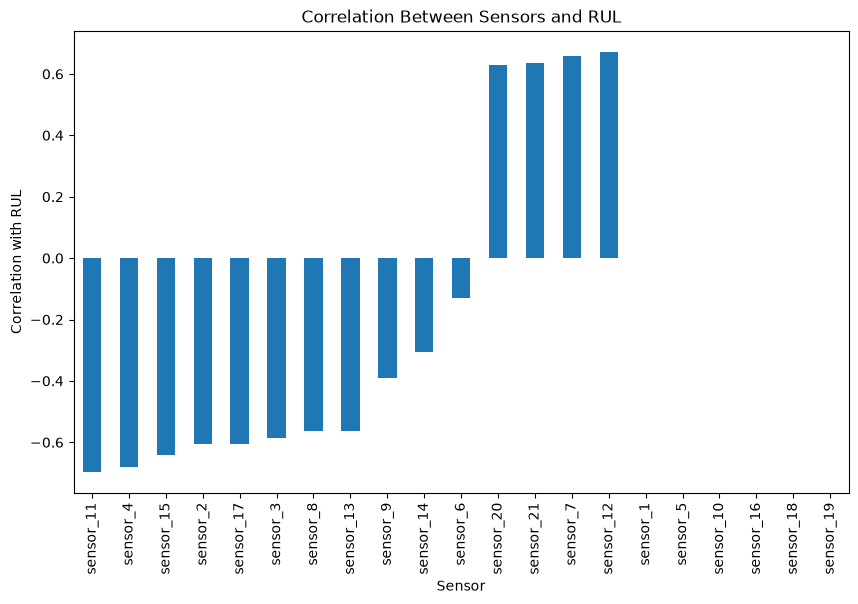

In [26]:
plt.figure(figsize=(10, 6))

sensor_corr.sort_values().plot(kind="bar")

plt.xlabel("Sensor")
plt.ylabel("Correlation with RUL")
plt.title("Correlation Between Sensors and RUL")

plt.show()

In [27]:
low_variance_sensors = sensor_std[sensor_std < 0.01].index.tolist()

print("低方差传感器：")
print(low_variance_sensors)

低方差传感器：
['sensor_1', 'sensor_10', 'sensor_19', 'sensor_18', 'sensor_16', 'sensor_5', 'sensor_6']


In [28]:
selected_sensors = [
    sensor for sensor in sensor_cols
    if sensor not in low_variance_sensors
]

print("保留的传感器数量：", len(selected_sensors))
print(selected_sensors)

保留的传感器数量： 14
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [29]:
X = train_df[selected_sensors]

y = train_df["RUL"]

print("X形状：", X.shape)
print("y形状：", y.shape)

X形状： (20631, 14)
y形状： (20631,)


In [30]:
from sklearn.model_selection import train_test_split

unit_ids = train_df["unit"].unique()

train_units, val_units = train_test_split(
    unit_ids,
    test_size=0.2,
    random_state=42
)

print("训练发动机数量：", len(train_units))
print("验证发动机数量：", len(val_units))

训练发动机数量： 80
验证发动机数量： 20


In [31]:
train_data = train_df[train_df["unit"].isin(train_units)].copy()
val_data = train_df[train_df["unit"].isin(val_units)].copy()

print("训练集数据量：", train_data.shape)
print("验证集数据量：", val_data.shape)

训练集数据量： (16561, 28)
验证集数据量： (4070, 28)


In [32]:
X_train = train_data[selected_sensors]
y_train = train_data["RUL"]

X_val = val_data[selected_sensors]
y_val = val_data["RUL"]

print("X_train：", X_train.shape)
print("y_train：", y_train.shape)

print("X_val：", X_val.shape)
print("y_val：", y_val.shape)

X_train： (16561, 14)
y_train： (16561,)
X_val： (4070, 14)
y_val： (4070,)


In [33]:
overlap = set(train_units) & set(val_units)

print("训练集和验证集重复发动机：", overlap)

训练集和验证集重复发动机： set()


In [34]:
from sklearn import set_config

set_config(display="text")

In [35]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [36]:
rf_model.fit(X_train, y_train);

print("随机森林训练完成")
print("决策树数量：", len(rf_model.estimators_))

随机森林训练完成
决策树数量： 100


In [37]:
y_pred = rf_model.predict(X_val)

print("前10个真实RUL：")
print(y_val.values[:10])

print("\n前10个预测RUL：")
print(np.round(y_pred[:10], 2))

前10个真实RUL：
[191 190 189 188 187 186 185 184 183 182]

前10个预测RUL：
[164.14 178.24 176.31 209.28 161.64 199.68 180.89 190.35 182.8  199.95]


In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_val, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_val, y_pred)
)

print("Random Forest MAE：", round(mae, 2))
print("Random Forest RMSE：", round(rmse, 2))

Random Forest MAE： 25.88
Random Forest RMSE： 35.41


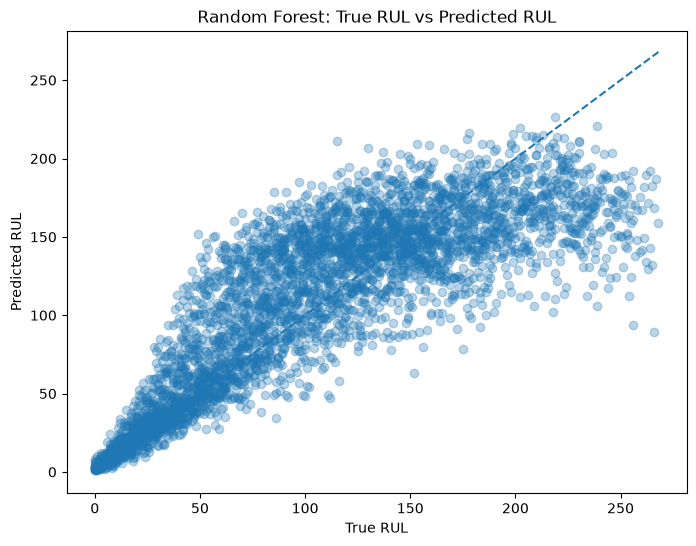

In [39]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_val,
    y_pred,
    alpha=0.3
)

min_rul = min(y_val.min(), y_pred.min())
max_rul = max(y_val.max(), y_pred.max())

plt.plot(
    [min_rul, max_rul],
    [min_rul, max_rul],
    linestyle="--"
)

plt.xlabel("True RUL")
plt.ylabel("Predicted RUL")
plt.title("Random Forest: True RUL vs Predicted RUL")

plt.show()

In [40]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=selected_sensors
).sort_values(ascending=False)

feature_importance

sensor_11    0.433971
sensor_9     0.128988
sensor_4     0.080907
sensor_12    0.049602
sensor_14    0.043804
sensor_7     0.040703
sensor_15    0.037418
sensor_21    0.035539
sensor_3     0.033440
sensor_2     0.031374
sensor_20    0.027507
sensor_8     0.023144
sensor_13    0.022828
sensor_17    0.010775
dtype: float64

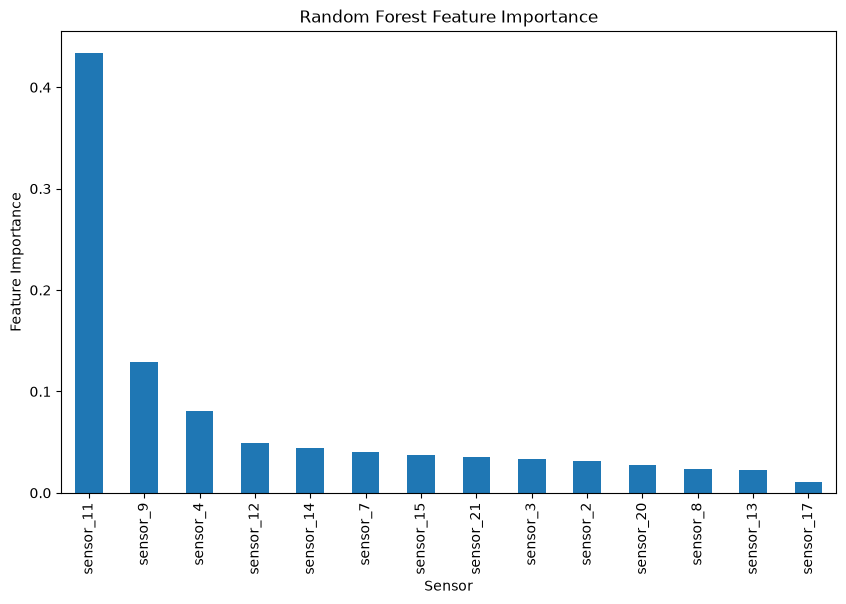

In [41]:
plt.figure(figsize=(10, 6))

feature_importance.plot(kind="bar")

plt.xlabel("Sensor")
plt.ylabel("Feature Importance")
plt.title("Random Forest Feature Importance")

plt.show()

In [42]:
y_pred_rf = rf_model.predict(X_val)

print("前10个真实RUL：")
print(y_val.values[:10])

print("\n前10个预测RUL：")
print(np.round(y_pred_rf[:10], 2))

前10个真实RUL：
[191 190 189 188 187 186 185 184 183 182]

前10个预测RUL：
[164.14 178.24 176.31 209.28 161.64 199.68 180.89 190.35 182.8  199.95]


In [43]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

rf_mae = mean_absolute_error(y_val, y_pred_rf)

rf_rmse = np.sqrt(
    mean_squared_error(y_val, y_pred_rf)
)

print("Random Forest MAE：", round(rf_mae, 2))
print("Random Forest RMSE：", round(rf_rmse, 2))

Random Forest MAE： 25.88
Random Forest RMSE： 35.41


In [44]:
model_results = pd.DataFrame({
    "Model": ["Random Forest"],
    "MAE": [rf_mae],
    "RMSE": [rf_rmse]
})

model_results

,Model,MAE,RMSE
0,Random Forest,25.879071,35.407605


In [45]:
import xgboost as xgb

print("XGBoost版本：", xgb.__version__)

XGBoost版本： 3.2.0


In [46]:
%pip install xgboost

Looking in indexes: https://mirrors.tuna.tsinghua.edu.cn/pypi/web/simple
Note: you may need to restart the kernel to use updated packages.


In [47]:
import xgboost as xgb
print("XGBoost版本：", xgb.__version__)

XGBoost版本： 3.2.0


In [48]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

In [49]:
xgb_model.fit(X_train, y_train)

print("XGBoost训练完成")

XGBoost训练完成


In [50]:
y_pred_xgb = xgb_model.predict(X_val)

print("前10个真实RUL：")
print(y_val.values[:10])

print("\n前10个XGBoost预测RUL：")
print(np.round(y_pred_xgb[:10], 2))

前10个真实RUL：
[191 190 189 188 187 186 185 184 183 182]

前10个XGBoost预测RUL：
[178.43 171.49 178.97 185.23 177.22 186.59 169.01 185.71 188.54 180.76]


In [51]:
xgb_mae = mean_absolute_error(y_val, y_pred_xgb)

xgb_rmse = np.sqrt(
    mean_squared_error(y_val, y_pred_xgb)
)

print("XGBoost MAE：", round(xgb_mae, 2))
print("XGBoost RMSE：", round(xgb_rmse, 2))

XGBoost MAE： 25.71
XGBoost RMSE： 35.22


In [52]:
new_result = pd.DataFrame({
    "Model": ["XGBoost"],
    "MAE": [xgb_mae],
    "RMSE": [xgb_rmse]
})

model_results = pd.concat(
    [model_results, new_result],
    ignore_index=True
)

model_results

,Model,MAE,RMSE
0,Random Forest,25.879071,35.407605
1,XGBoost,25.714445,35.224112


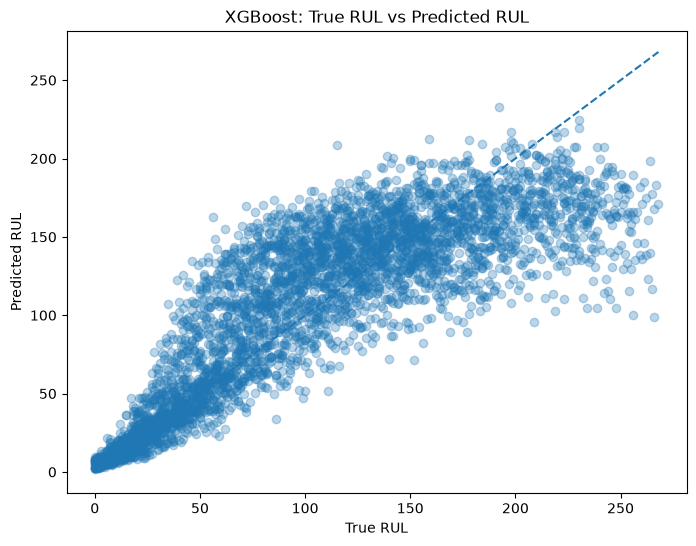

In [53]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_val,
    y_pred_xgb,
    alpha=0.3
)

min_rul = min(y_val.min(), y_pred_xgb.min())
max_rul = max(y_val.max(), y_pred_xgb.max())

plt.plot(
    [min_rul, max_rul],
    [min_rul, max_rul],
    linestyle="--"
)

plt.xlabel("True RUL")
plt.ylabel("Predicted RUL")
plt.title("XGBoost: True RUL vs Predicted RUL")

plt.show()

In [54]:
xgb_importance = pd.Series(
    xgb_model.feature_importances_,
    index=selected_sensors
).sort_values(ascending=False)

xgb_importance

sensor_11    0.329386
sensor_4     0.208157
sensor_12    0.095511
sensor_9     0.090758
sensor_7     0.046693
sensor_20    0.040851
sensor_15    0.037582
sensor_14    0.034251
sensor_17    0.029654
sensor_21    0.026475
sensor_13    0.016680
sensor_8     0.015667
sensor_3     0.014336
sensor_2     0.013999
dtype: float32

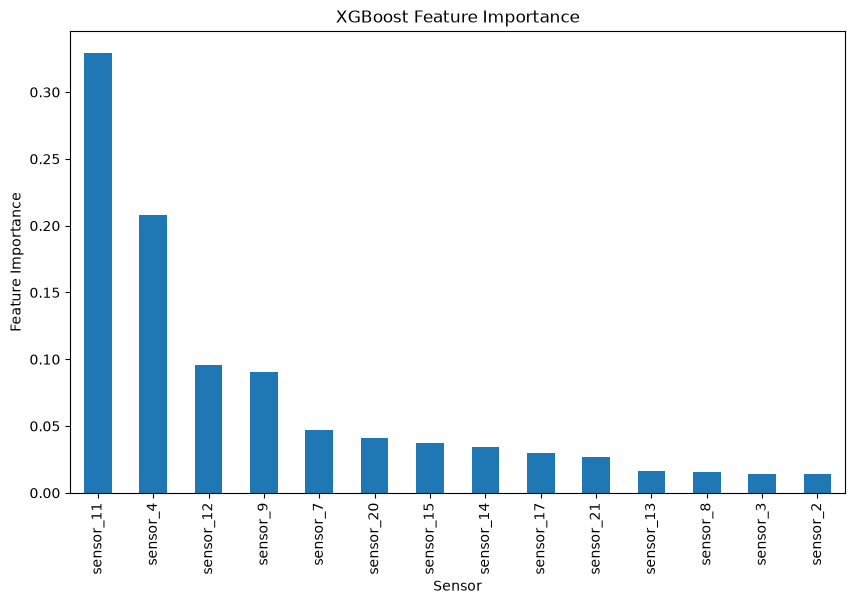

In [55]:
plt.figure(figsize=(10, 6))

xgb_importance.plot(kind="bar")

plt.xlabel("Sensor")
plt.ylabel("Feature Importance")
plt.title("XGBoost Feature Importance")

plt.show()

In [56]:
model_results

,Model,MAE,RMSE
0,Random Forest,25.879071,35.407605
1,XGBoost,25.714445,35.224112


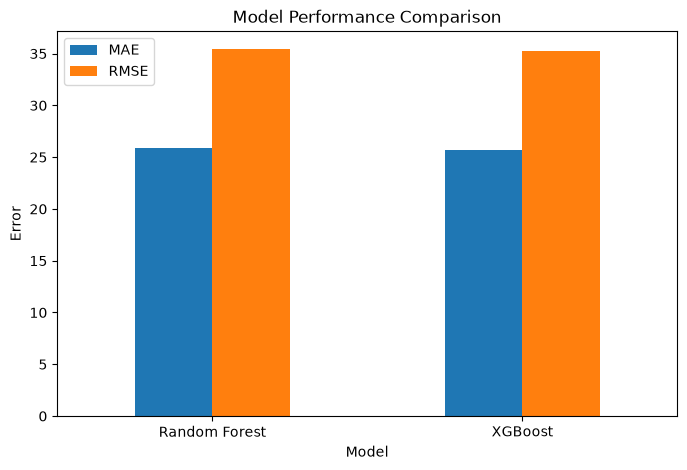

In [57]:
model_results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylabel("Error")
plt.title("Model Performance Comparison")
plt.xticks(rotation=0)

plt.show()

In [58]:
model_results.to_csv(
    "../results/model_results.csv",
    index=False
)

In [59]:
import joblib

joblib.dump(
    rf_model,
    "../models/random_forest_model.pkl"
)

joblib.dump(
    xgb_model,
    "../models/xgboost_model.pkl"
)

print("模型保存完成")

模型保存完成


In [60]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

train_scaled = train_data.copy()
val_scaled = val_data.copy()

train_scaled[selected_sensors] = scaler.fit_transform(
    train_data[selected_sensors]
)

val_scaled[selected_sensors] = scaler.transform(
    val_data[selected_sensors]
)

print("标准化完成")

标准化完成


In [61]:
def create_sequences(df, feature_cols, seq_len=30):
    
    X_seq = []
    y_seq = []
    end_indices = []

    for unit in df["unit"].unique():

        unit_df = df[
            df["unit"] == unit
        ].sort_values("cycle")

        features = unit_df[feature_cols].values
        targets = unit_df["RUL"].values

        for i in range(seq_len - 1, len(unit_df)):

            X_seq.append(
                features[i-seq_len+1:i+1]
            )

            y_seq.append(
                targets[i]
            )

            end_indices.append(
                unit_df.index[i]
            )

    return (
        np.array(X_seq),
        np.array(y_seq),
        np.array(end_indices)
    )

In [62]:
X_train_seq, y_train_seq, train_end_idx = create_sequences(
    train_scaled,
    selected_sensors,
    seq_len=30
)

X_val_seq, y_val_seq, val_end_idx = create_sequences(
    val_scaled,
    selected_sensors,
    seq_len=30
)

print("LSTM训练输入形状：", X_train_seq.shape)
print("LSTM训练标签形状：", y_train_seq.shape)

print("LSTM验证输入形状：", X_val_seq.shape)
print("LSTM验证标签形状：", y_val_seq.shape)

LSTM训练输入形状： (14241, 30, 14)
LSTM训练标签形状： (14241,)
LSTM验证输入形状： (3490, 30, 14)
LSTM验证标签形状： (3490,)


In [63]:
import torch

print("PyTorch版本：", torch.__version__)
print("是否支持GPU：", torch.cuda.is_available())

PyTorch版本： 2.14.0+cpu
是否支持GPU： False


In [64]:
%pip install torch

Looking in indexes: https://mirrors.tuna.tsinghua.edu.cn/pypi/web/simple
Note: you may need to restart the kernel to use updated packages.


In [65]:
X_train_seq

array([[[-1.58119086, -1.09266247, -1.96301407, ..., -1.42624592,
          0.6786845 ,  1.5644361 ],
        [-1.72172228, -0.56515529, -1.75666396, ..., -0.77952854,
          1.34584413,  1.09889538],
        [-2.26377202, -0.35645308, -1.10638223, ..., -1.42624592,
          1.62382731,  1.25252381],
        ...,
        [-1.28005212, -1.46076717, -1.27480855, ..., -2.07296329,
          0.73428113,  1.38753063],
        [-1.19974845, -1.10252242, -1.20453797, ..., -2.07296329,
          0.8454744 ,  1.25159273],
        [-1.80202594, -0.02778817, -1.54027518, ..., -1.42624592,
          1.56823067,  1.00578723]],

       [[-1.72172228, -0.56515529, -1.75666396, ..., -0.77952854,
          1.34584413,  1.09889538],
        [-2.26377202, -0.35645308, -1.10638223, ..., -1.42624592,
          1.62382731,  1.25252381],
        [-2.00278511, -1.04171941, -1.42761917, ..., -1.42624592,
          1.73502058,  1.9759741 ],
        ...,
        [-1.19974845, -1.10252242, -1.20453797, ..., -

In [66]:
import torch
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(
    X_train_seq,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_seq,
    dtype=torch.float32
).unsqueeze(1)

X_val_tensor = torch.tensor(
    X_val_seq,
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val_seq,
    dtype=torch.float32
).unsqueeze(1)

In [67]:
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

print("训练Batch数量：", len(train_loader))
print("验证Batch数量：", len(val_loader))

训练Batch数量： 223
验证Batch数量： 55


In [68]:
import torch
import torch.nn as nn

class RULLSTM(nn.Module):
    def __init__(self, input_size=14, hidden_size=64, num_layers=1):
        super(RULLSTM, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        lstm_out, _ = self.lstm(x)

        last_output = lstm_out[:, -1, :]

        rul = self.fc(last_output)

        return rul

In [69]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

lstm_model = RULLSTM(
    input_size=len(selected_sensors),
    hidden_size=64,
    num_layers=1
).to(device)

print("当前设备：", device)
print(lstm_model)

当前设备： cpu
RULLSTM(
  (lstm): LSTM(14, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [70]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

In [71]:
num_epochs = 30

train_losses = []
val_losses = []

for epoch in range(num_epochs):

    # --------------------
    # 训练阶段
    # --------------------
    lstm_model.train()

    total_train_loss = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = lstm_model(X_batch)

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = (
        total_train_loss / len(train_loader)
    )

    # --------------------
    # 验证阶段
    # --------------------
    lstm_model.eval()

    total_val_loss = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = lstm_model(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            total_val_loss += loss.item()

    avg_val_loss = (
        total_val_loss / len(val_loader)
    )

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    print(
        f"Epoch {epoch+1:02d}/{num_epochs} | "
        f"Train Loss: {avg_train_loss:.2f} | "
        f"Val Loss: {avg_val_loss:.2f}"
    )

Epoch 01/30 | Train Loss: 10978.92 | Val Loss: 8465.17
Epoch 02/30 | Train Loss: 8534.28 | Val Loss: 6641.22
Epoch 03/30 | Train Loss: 6855.93 | Val Loss: 5266.88
Epoch 04/30 | Train Loss: 5568.08 | Val Loss: 4207.35
Epoch 05/30 | Train Loss: 4558.16 | Val Loss: 3379.29
Epoch 06/30 | Train Loss: 3773.56 | Val Loss: 2748.54
Epoch 07/30 | Train Loss: 3163.12 | Val Loss: 2254.36
Epoch 08/30 | Train Loss: 2679.19 | Val Loss: 1866.71
Epoch 09/30 | Train Loss: 2309.64 | Val Loss: 1592.17
Epoch 10/30 | Train Loss: 2009.84 | Val Loss: 1336.76
Epoch 11/30 | Train Loss: 1779.27 | Val Loss: 1138.55
Epoch 12/30 | Train Loss: 1603.80 | Val Loss: 1006.37
Epoch 13/30 | Train Loss: 1445.84 | Val Loss: 884.06
Epoch 14/30 | Train Loss: 1334.89 | Val Loss: 864.66
Epoch 15/30 | Train Loss: 1236.85 | Val Loss: 731.09
Epoch 16/30 | Train Loss: 1162.07 | Val Loss: 819.41
Epoch 17/30 | Train Loss: 1089.96 | Val Loss: 699.96
Epoch 18/30 | Train Loss: 1043.20 | Val Loss: 654.20
Epoch 19/30 | Train Loss: 986.83 

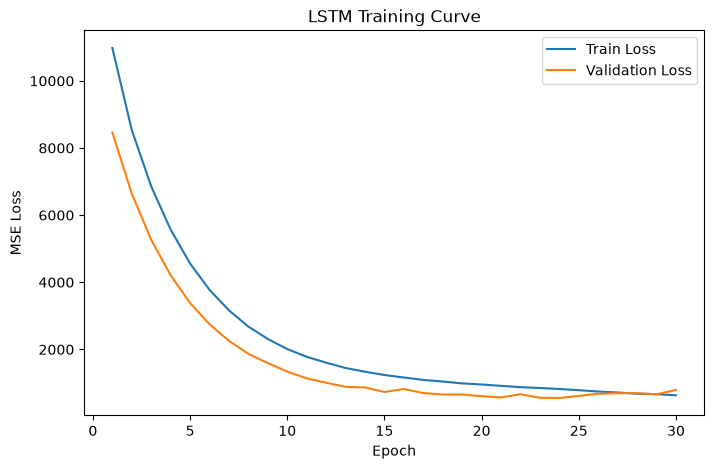

In [72]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, num_epochs + 1),
    train_losses,
    label="Train Loss"
)

plt.plot(
    range(1, num_epochs + 1),
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training Curve")
plt.legend()

plt.show()

In [73]:
lstm_model.eval()

predictions = []

with torch.no_grad():

    for X_batch, _ in val_loader:

        X_batch = X_batch.to(device)

        pred = lstm_model(X_batch)

        predictions.extend(
            pred.cpu().numpy().flatten()
        )

y_pred_lstm = np.array(predictions)

print("前10个真实RUL：")
print(y_val_seq[:10])

print("\n前10个LSTM预测RUL：")
print(np.round(y_pred_lstm[:10], 2))

前10个真实RUL：
[162 161 160 159 158 157 156 155 154 153]

前10个LSTM预测RUL：
[189.98 189.87 190.07 190.08 188.9  188.82 188.9  190.08 190.52 190.63]


In [74]:
lstm_mae = mean_absolute_error(
    y_val_seq,
    y_pred_lstm
)

lstm_rmse = np.sqrt(
    mean_squared_error(
        y_val_seq,
        y_pred_lstm
    )
)

print(
    "LSTM MAE：",
    round(lstm_mae, 2)
)

print(
    "LSTM RMSE：",
    round(lstm_rmse, 2)
)

LSTM MAE： 19.54
LSTM RMSE： 28.26


In [75]:
X_val_fair = val_data.loc[
    val_end_idx,
    selected_sensors
]

y_val_fair = val_data.loc[
    val_end_idx,
    "RUL"
].values

In [76]:
y_pred_rf_fair = rf_model.predict(
    X_val_fair
)

rf_mae_fair = mean_absolute_error(
    y_val_fair,
    y_pred_rf_fair
)

rf_rmse_fair = np.sqrt(
    mean_squared_error(
        y_val_fair,
        y_pred_rf_fair
    )
)

In [77]:
y_pred_xgb_fair = xgb_model.predict(
    X_val_fair
)

xgb_mae_fair = mean_absolute_error(
    y_val_fair,
    y_pred_xgb_fair
)

xgb_rmse_fair = np.sqrt(
    mean_squared_error(
        y_val_fair,
        y_pred_xgb_fair
    )
)

In [78]:
fair_model_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "LSTM"
    ],
    "MAE": [
        rf_mae_fair,
        xgb_mae_fair,
        lstm_mae
    ],
    "RMSE": [
        rf_rmse_fair,
        xgb_rmse_fair,
        lstm_rmse
    ]
})

fair_model_results

,Model,MAE,RMSE
0,Random Forest,23.476072,32.031207
1,XGBoost,23.259352,31.614462
2,LSTM,19.536484,28.255489


In [79]:
fair_model_results.to_csv(
    "../results/validation_model_comparison.csv",
    index=False
)

print("验证集模型结果已保存")

验证集模型结果已保存


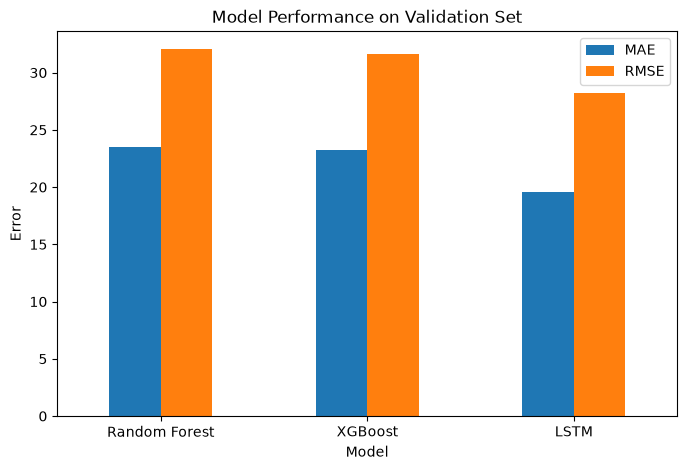

In [80]:
fair_model_results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylabel("Error")
plt.title("Model Performance on Validation Set")
plt.xticks(rotation=0)
plt.show()

In [81]:
test_path = "../data/FD001/test_FD001.txt"
rul_path = "../data/FD001/RUL_FD001.txt"

test_df = pd.read_csv(
    test_path,
    sep=r"\s+",
    header=None
)

test_rul = pd.read_csv(
    rul_path,
    sep=r"\s+",
    header=None
)

In [82]:
print("测试集形状：", test_df.shape)
print("真实RUL数量：", test_rul.shape)

test_df.head()

测试集形状： (13096, 26)
真实RUL数量： (100, 1)


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


In [83]:
test_df.columns = column_names

test_df.head()

,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


In [84]:
test_last = (
    test_df
    .sort_values(["unit", "cycle"])
    .groupby("unit")
    .tail(1)
    .sort_values("unit")
)

print(test_last.shape)
test_last[["unit", "cycle"]].head()

(100, 26)


,unit,cycle
30,1,31
79,2,49
205,3,126
311,4,106
409,5,98


In [85]:
X_test_tree = test_last[selected_sensors]

In [86]:
rf_test_pred = rf_model.predict(X_test_tree)

xgb_test_pred = xgb_model.predict(X_test_tree)

In [87]:
y_test_true = test_rul.iloc[:, 0].values

In [88]:
rf_test_mae = mean_absolute_error(
    y_test_true,
    rf_test_pred
)

rf_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_true,
        rf_test_pred
    )
)

xgb_test_mae = mean_absolute_error(
    y_test_true,
    xgb_test_pred
)

xgb_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_true,
        xgb_test_pred
    )
)

print("RF Test MAE:", round(rf_test_mae, 2))
print("RF Test RMSE:", round(rf_test_rmse, 2))

print("XGB Test MAE:", round(xgb_test_mae, 2))
print("XGB Test RMSE:", round(xgb_test_rmse, 2))

RF Test MAE: 25.11
RF Test RMSE: 34.38
XGB Test MAE: 23.54
XGB Test RMSE: 32.94


In [89]:
test_scaled = test_df.copy()

test_scaled[selected_sensors] = scaler.transform(
    test_df[selected_sensors]
)

In [90]:
def create_test_sequences(
    df,
    feature_cols,
    seq_len=30
):
    X_seq = []
    units = []

    for unit in df["unit"].unique():

        unit_df = (
            df[df["unit"] == unit]
            .sort_values("cycle")
        )

        features = unit_df[
            feature_cols
        ].values

        if len(features) >= seq_len:

            seq = features[-seq_len:]

        else:

            # 如果序列不足30步，
            # 用最早状态进行前端填充
            pad_length = seq_len - len(features)

            padding = np.repeat(
                features[[0]],
                pad_length,
                axis=0
            )

            seq = np.vstack([
                padding,
                features
            ])

        X_seq.append(seq)
        units.append(unit)

    return (
        np.array(X_seq),
        np.array(units)
    )

In [91]:
X_test_seq, test_units = create_test_sequences(
    test_scaled,
    selected_sensors,
    seq_len=30
)

print("LSTM测试数据形状：", X_test_seq.shape)

LSTM测试数据形状： (100, 30, 14)


In [92]:
X_test_tensor = torch.tensor(
    X_test_seq,
    dtype=torch.float32
).to(device)

In [93]:
lstm_model.eval()

with torch.no_grad():

    lstm_test_pred = (
        lstm_model(X_test_tensor)
        .cpu()
        .numpy()
        .flatten()
    )

In [94]:
lstm_test_mae = mean_absolute_error(
    y_test_true,
    lstm_test_pred
)

lstm_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_true,
        lstm_test_pred
    )
)

print(
    "LSTM Test MAE:",
    round(lstm_test_mae, 2)
)

print(
    "LSTM Test RMSE:",
    round(lstm_test_rmse, 2)
)

LSTM Test MAE: 19.96
LSTM Test RMSE: 28.98


In [95]:
test_model_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "LSTM"
    ],
    "MAE": [
        rf_test_mae,
        xgb_test_mae,
        lstm_test_mae
    ],
    "RMSE": [
        rf_test_rmse,
        xgb_test_rmse,
        lstm_test_rmse
    ]
})

test_model_results

,Model,MAE,RMSE
0,Random Forest,25.108100,34.376223
1,XGBoost,23.535965,32.940798
2,LSTM,19.955904,28.982384


In [96]:
test_model_results.to_csv(
    "../results/test_model_results.csv",
    index=False
)

test_model_results

,Model,MAE,RMSE
0,Random Forest,25.108100,34.376223
1,XGBoost,23.535965,32.940798
2,LSTM,19.955904,28.982384


In [97]:
import joblib
import torch

joblib.dump(
    rf_model,
    "../models/random_forest_model.pkl"
)

joblib.dump(
    xgb_model,
    "../models/xgboost_model.pkl"
)

torch.save(
    lstm_model.state_dict(),
    "../models/lstm_model.pth"
)

print("模型和测试结果保存完成")

模型和测试结果保存完成


In [98]:
xgb_residuals = np.abs(
    y_val.values - y_pred_xgb
)

print("残差数量：", len(xgb_residuals))
print("平均绝对残差：", round(xgb_residuals.mean(), 2))

残差数量： 4070
平均绝对残差： 25.71


In [99]:
alpha = 0.10

q = np.quantile(
    xgb_residuals,
    1 - alpha
)

print(
    "90%预测区间半宽：",
    round(q, 2)
)

90%预测区间半宽： 60.31


In [100]:
lower_xgb = np.maximum(
    0,
    xgb_test_pred - q
)

upper_xgb = xgb_test_pred + q

In [101]:
uncertainty_results = pd.DataFrame({
    "True_RUL": y_test_true,
    "Predicted_RUL": xgb_test_pred,
    "Lower_90": lower_xgb,
    "Upper_90": upper_xgb
})

uncertainty_results.head(10)

,True_RUL,Predicted_RUL,Lower_90,Upper_90
0,112,174.228241,113.921079,234.535403
1,98,152.412125,92.104963,212.719286
2,69,63.955173,3.648012,124.262335
3,82,100.739487,40.432325,161.046648
4,91,127.170792,66.863630,187.477953
5,93,129.111572,68.804411,189.418734
6,91,119.753998,59.446836,180.061160
7,95,107.228592,46.921430,167.535754
8,111,116.760536,56.453374,177.067698
9,96,132.845474,72.538313,193.152636


In [102]:
covered = (
    (y_test_true >= lower_xgb)
    &
    (y_test_true <= upper_xgb)
)

coverage = covered.mean()

print(
    "实际覆盖率：",
    round(coverage * 100, 2),
    "%"
)

实际覆盖率： 91.0 %


In [103]:
interval_width = (
    upper_xgb - lower_xgb
)

mean_interval_width = (
    interval_width.mean()
)

print(
    "平均预测区间宽度：",
    round(mean_interval_width, 2)
)

平均预测区间宽度： 110.14


In [104]:
X_test_clean = X_test_tree.copy()

print("正常测试数据形状：", X_test_clean.shape)

正常测试数据形状： (100, 14)


In [105]:
sensor_train_std = train_data[selected_sensors].std()

sensor_train_std

sensor_2      0.498124
sensor_3      6.085409
sensor_4      8.965616
sensor_7      0.877772
sensor_8      0.070647
sensor_9     22.659801
sensor_11     0.265733
sensor_12     0.734990
sensor_13     0.071709
sensor_14    19.587082
sensor_15     0.037508
sensor_17     1.546317
sensor_20     0.179872
sensor_21     0.107405
dtype: float64

In [106]:
def inject_gaussian_noise(
    X,
    sensor_std,
    severity=0.5,
    random_state=42
):
    rng = np.random.default_rng(random_state)

    X_fault = X.copy()

    for sensor in X.columns:
        noise = rng.normal(
            loc=0,
            scale=sensor_std[sensor] * severity,
            size=len(X)
        )

        X_fault[sensor] = X_fault[sensor] + noise

    return X_fault

In [107]:
noise_levels = [
    0.0,
    0.25,
    0.5,
    1.0,
    2.0
]

noise_results = []

for severity in noise_levels:

    if severity == 0:
        X_fault = X_test_clean.copy()

    else:
        X_fault = inject_gaussian_noise(
            X_test_clean,
            sensor_train_std,
            severity=severity
        )

    pred = xgb_model.predict(X_fault)

    mae = mean_absolute_error(
        y_test_true,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_true,
            pred
        )
    )

    noise_results.append({
        "Severity": severity,
        "MAE": mae,
        "RMSE": rmse
    })

noise_results = pd.DataFrame(noise_results)

noise_results

,Severity,MAE,RMSE
0,0.00,23.535965,32.940798
1,0.25,25.967897,35.028077
2,0.50,27.277298,36.284677
3,1.00,33.350460,43.055333
4,2.00,48.882641,60.600942


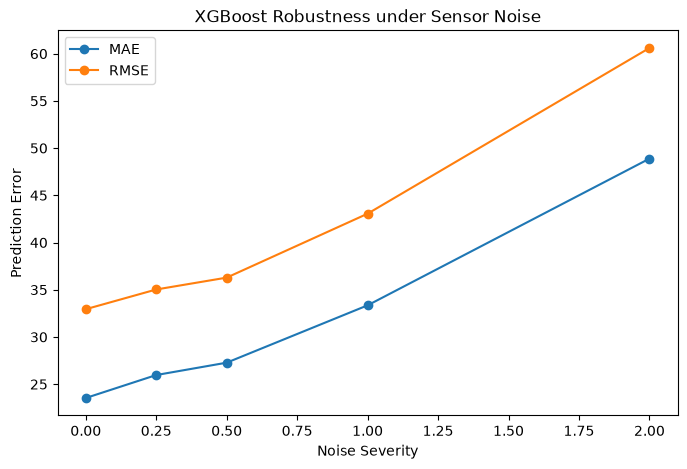

In [108]:
plt.figure(figsize=(8, 5))

plt.plot(
    noise_results["Severity"],
    noise_results["MAE"],
    marker="o",
    label="MAE"
)

plt.plot(
    noise_results["Severity"],
    noise_results["RMSE"],
    marker="o",
    label="RMSE"
)

plt.xlabel("Noise Severity")
plt.ylabel("Prediction Error")
plt.title("XGBoost Robustness under Sensor Noise")
plt.legend()

plt.show()

In [109]:
def inject_bias(
    X,
    sensor_std,
    severity=0.5
):
    X_fault = X.copy()

    for sensor in X.columns:

        bias = (
            sensor_std[sensor]
            * severity
        )

        X_fault[sensor] = (
            X_fault[sensor] + bias
        )

    return X_fault

In [110]:
bias_levels = [
    0.0,
    0.25,
    0.5,
    1.0,
    2.0
]

bias_results = []

for severity in bias_levels:

    if severity == 0:
        X_fault = X_test_clean.copy()

    else:
        X_fault = inject_bias(
            X_test_clean,
            sensor_train_std,
            severity=severity
        )

    pred = xgb_model.predict(X_fault)

    mae = mean_absolute_error(
        y_test_true,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_true,
            pred
        )
    )

    bias_results.append({
        "Severity": severity,
        "MAE": mae,
        "RMSE": rmse
    })

bias_results = pd.DataFrame(
    bias_results
)

bias_results

,Severity,MAE,RMSE
0,0.00,23.535965,32.940798
1,0.25,19.678514,27.748186
2,0.50,17.924688,24.496635
3,1.00,22.381197,28.834281
4,2.00,19.497822,24.190892


In [111]:
X_stuck = X_test_clean.copy()

stuck_value = train_data[
    "sensor_11"
].median()

X_stuck["sensor_11"] = stuck_value

In [112]:
stuck_pred = xgb_model.predict(
    X_stuck
)

stuck_mae = mean_absolute_error(
    y_test_true,
    stuck_pred
)

stuck_rmse = np.sqrt(
    mean_squared_error(
        y_test_true,
        stuck_pred
    )
)

print(
    "Sensor 11 Stuck MAE:",
    round(stuck_mae, 2)
)

print(
    "Sensor 11 Stuck RMSE:",
    round(stuck_rmse, 2)
)

Sensor 11 Stuck MAE: 28.53
Sensor 11 Stuck RMSE: 35.45


In [113]:
def inject_missing(
    X,
    missing_rate=0.1,
    random_state=42
):
    rng = np.random.default_rng(
        random_state
    )

    X_fault = X.copy()

    mask = rng.random(
        X_fault.shape
    ) < missing_rate

    X_fault = X_fault.mask(mask)

    return X_fault

In [114]:
missing_levels = [
    0.0,
    0.05,
    0.10,
    0.20,
    0.30
]

missing_results = []

for rate in missing_levels:

    if rate == 0:
        X_fault = X_test_clean.copy()

    else:
        X_fault = inject_missing(
            X_test_clean,
            missing_rate=rate
        )

    pred = xgb_model.predict(
        X_fault
    )

    mae = mean_absolute_error(
        y_test_true,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_true,
            pred
        )
    )

    missing_results.append({
        "Missing Rate": rate,
        "MAE": mae,
        "RMSE": rmse
    })

missing_results = pd.DataFrame(
    missing_results
)

missing_results

,Missing Rate,MAE,RMSE
0,0.00,23.535965,32.940798
1,0.05,24.764141,34.487113
2,0.10,26.683611,35.686431
3,0.20,30.274546,40.550888
4,0.30,31.512417,40.716570


In [115]:
robustness_summary = pd.DataFrame({
    "Condition": [
        "Clean",
        "Gaussian Noise (1.0)",
        "Bias (1.0)",
        "Sensor 11 Stuck",
        "Missing 20%"
    ],
    "MAE": [
        xgb_test_mae,
        noise_results.loc[
            noise_results["Severity"] == 1.0,
            "MAE"
        ].values[0],
        bias_results.loc[
            bias_results["Severity"] == 1.0,
            "MAE"
        ].values[0],
        stuck_mae,
        missing_results.loc[
            missing_results["Missing Rate"] == 0.20,
            "MAE"
        ].values[0]
    ],
    "RMSE": [
        xgb_test_rmse,
        noise_results.loc[
            noise_results["Severity"] == 1.0,
            "RMSE"
        ].values[0],
        bias_results.loc[
            bias_results["Severity"] == 1.0,
            "RMSE"
        ].values[0],
        stuck_rmse,
        missing_results.loc[
            missing_results["Missing Rate"] == 0.20,
            "RMSE"
        ].values[0]
    ]
})

robustness_summary

,Condition,MAE,RMSE
0,Clean,23.535965,32.940798
1,Gaussian Noise (1.0),33.350460,43.055333
2,Bias (1.0),22.381197,28.834281
3,Sensor 11 Stuck,28.525572,35.447684
4,Missing 20%,30.274546,40.550888


In [116]:
robustness_summary.to_csv(
    "../results/robustness_summary.csv",
    index=False
)

robustness_summary

,Condition,MAE,RMSE
0,Clean,23.535965,32.940798
1,Gaussian Noise (1.0),33.350460,43.055333
2,Bias (1.0),22.381197,28.834281
3,Sensor 11 Stuck,28.525572,35.447684
4,Missing 20%,30.274546,40.550888


In [117]:
ensemble_models = []

for seed in range(10):

    model = XGBRegressor(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=seed,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    ensemble_models.append(model)

print("Ensemble模型数量：", len(ensemble_models))

Ensemble模型数量： 10


In [118]:
ensemble_test_predictions = []

for model in ensemble_models:

    pred = model.predict(X_test_clean)

    ensemble_test_predictions.append(pred)

ensemble_test_predictions = np.array(
    ensemble_test_predictions
)

print(
    "预测矩阵形状：",
    ensemble_test_predictions.shape
)

预测矩阵形状： (10, 100)


In [119]:
ensemble_mean = ensemble_test_predictions.mean(axis=0)

ensemble_std = ensemble_test_predictions.std(axis=0)

print("前5台发动机平均预测：")
print(np.round(ensemble_mean[:5], 2))

print("\n前5台发动机预测标准差：")
print(np.round(ensemble_std[:5], 2))

前5台发动机平均预测：
[172.34 145.76  66.84  98.3  128.4 ]

前5台发动机预测标准差：
[3.09 3.35 3.64 2.82 3.82]


In [120]:
ensemble_abs_error = np.abs(
    y_test_true - ensemble_mean
)

In [121]:
uncertainty_error_df = pd.DataFrame({
    "True_RUL": y_test_true,
    "Predicted_RUL": ensemble_mean,
    "Absolute_Error": ensemble_abs_error,
    "Uncertainty": ensemble_std
})

uncertainty_error_df.head()

,True_RUL,Predicted_RUL,Absolute_Error,Uncertainty
0,112,172.338760,60.338760,3.091851
1,98,145.763809,47.763809,3.354252
2,69,66.843674,2.156326,3.643929
3,82,98.297142,16.297142,2.822909
4,91,128.400070,37.400070,3.815576


In [122]:
error_uncertainty_corr = np.corrcoef(
    ensemble_abs_error,
    ensemble_std
)[0, 1]

print(
    "预测误差与不确定性的相关系数：",
    round(error_uncertainty_corr, 3)
)

预测误差与不确定性的相关系数： 0.445


In [123]:
fault_datasets = {
    "Clean": X_test_clean,

    "Gaussian Noise (1.0)": inject_gaussian_noise(
        X_test_clean,
        sensor_train_std,
        severity=1.0
    ),

    "Bias (1.0)": inject_bias(
        X_test_clean,
        sensor_train_std,
        severity=1.0
    ),

    "Sensor 11 Stuck": X_stuck,

    "Missing 20%": inject_missing(
        X_test_clean,
        missing_rate=0.20
    )
}

In [124]:
ensemble_fault_results = []

for condition, X_fault in fault_datasets.items():

    preds = []

    for model in ensemble_models:

        pred = model.predict(X_fault)

        preds.append(pred)

    preds = np.array(preds)

    mean_pred = preds.mean(axis=0)

    uncertainty = preds.std(axis=0)

    mae = mean_absolute_error(
        y_test_true,
        mean_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_true,
            mean_pred
        )
    )

    mean_uncertainty = uncertainty.mean()

    ensemble_fault_results.append({
        "Condition": condition,
        "MAE": mae,
        "RMSE": rmse,
        "Mean_Uncertainty": mean_uncertainty
    })

ensemble_fault_results = pd.DataFrame(
    ensemble_fault_results
)

ensemble_fault_results

,Condition,MAE,RMSE,Mean_Uncertainty
0,Clean,23.665031,33.406113,2.368722
1,Gaussian Noise (1.0),34.255119,43.820156,6.205927
2,Bias (1.0),23.154335,29.621342,6.099011
3,Sensor 11 Stuck,28.693874,35.566545,2.658221
4,Missing 20%,29.585030,39.812512,6.157837


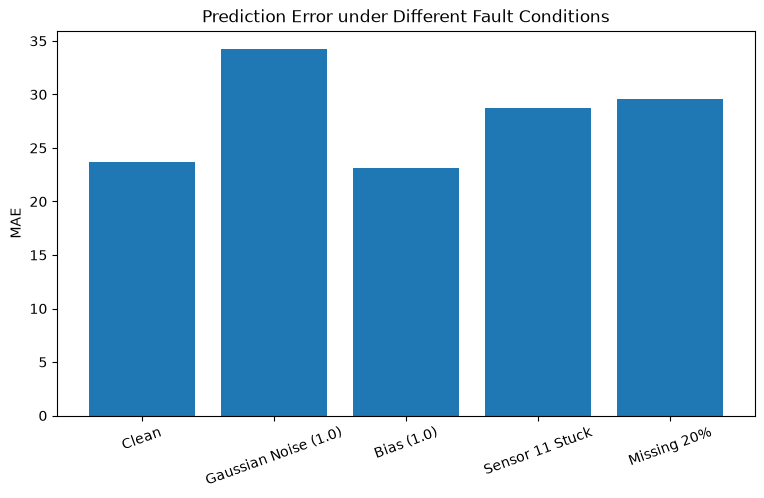

In [125]:
plt.figure(figsize=(9, 5))

plt.bar(
    ensemble_fault_results["Condition"],
    ensemble_fault_results["MAE"]
)

plt.ylabel("MAE")
plt.title("Prediction Error under Different Fault Conditions")
plt.xticks(rotation=20)

plt.show()

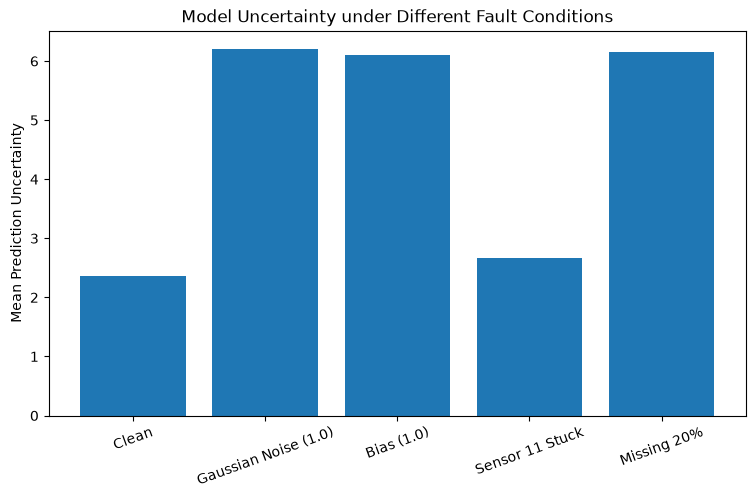

In [126]:
plt.figure(figsize=(9, 5))

plt.bar(
    ensemble_fault_results["Condition"],
    ensemble_fault_results["Mean_Uncertainty"]
)

plt.ylabel("Mean Prediction Uncertainty")
plt.title("Model Uncertainty under Different Fault Conditions")
plt.xticks(rotation=20)

plt.show()

In [127]:
uncertainty_error_df = pd.DataFrame({

    "True_RUL": y_test_true,

    "Predicted_RUL": ensemble_mean,

    "Absolute_Error": np.abs(
        y_test_true - ensemble_mean
    ),

    "Uncertainty": ensemble_std

})


uncertainty_error_df.head()

,True_RUL,Predicted_RUL,Absolute_Error,Uncertainty
0,112,172.338760,60.338760,3.091851
1,98,145.763809,47.763809,3.354252
2,69,66.843674,2.156326,3.643929
3,82,98.297142,16.297142,2.822909
4,91,128.400070,37.400070,3.815576


In [128]:
corr = np.corrcoef(
    uncertainty_error_df["Absolute_Error"],
    uncertainty_error_df["Uncertainty"]
)[0,1]


print(
    "误差-不确定性相关系数:",
    round(corr,3)
)

误差-不确定性相关系数: 0.445


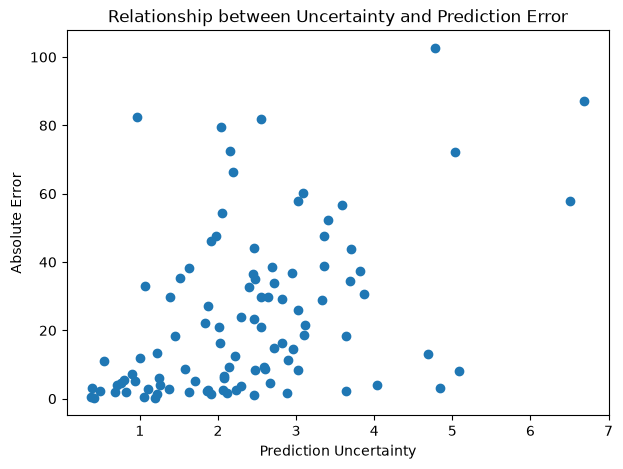

In [129]:
plt.figure(figsize=(7,5))

plt.scatter(
    uncertainty_error_df["Uncertainty"],
    uncertainty_error_df["Absolute_Error"]
)

plt.xlabel("Prediction Uncertainty")
plt.ylabel("Absolute Error")

plt.title(
    "Relationship between Uncertainty and Prediction Error"
)

plt.show()

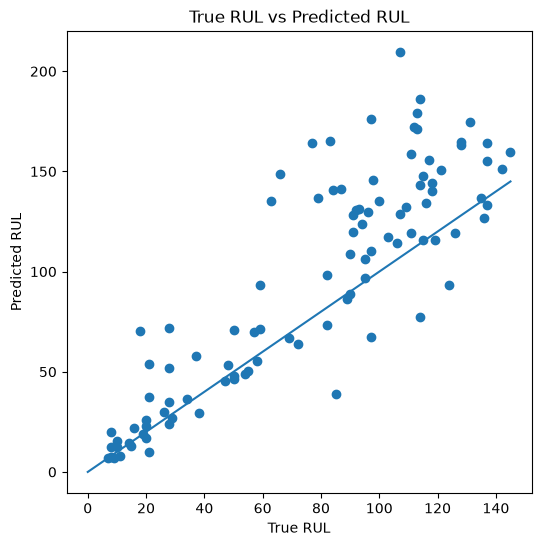

In [130]:
plt.figure(figsize=(6,6))

plt.scatter(
    y_test_true,
    ensemble_mean
)


plt.plot(
    [0, max(y_test_true)],
    [0, max(y_test_true)]
)


plt.xlabel("True RUL")
plt.ylabel("Predicted RUL")

plt.title(
    "True RUL vs Predicted RUL"
)


plt.show()

In [131]:
plt.savefig(
    "results/RUL_prediction.png",
    dpi=300,
    bbox_inches="tight"
)

FileNotFoundError: [Errno 2] No such file or directory: 'results/RUL_prediction.png'

<Figure size 640x480 with 0 Axes>

In [ ]:
clean_mae = ensemble_fault_results.loc[
    ensemble_fault_results["Condition"]=="Clean",
    "MAE"
].values[0]


ensemble_fault_results["Performance_Drop(%)"] = (
    ensemble_fault_results["MAE"] - clean_mae
) / clean_mae * 100


ensemble_fault_results

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    ensemble_fault_results["Condition"],
    ensemble_fault_results["Performance_Drop(%)"]
)

plt.ylabel(
    "Performance Degradation (%)"
)

plt.xlabel(
    "Fault Condition"
)

plt.title(
    "Impact of Sensor Faults on Prediction Performance"
)

plt.xticks(rotation=20)

plt.show()

In [ ]:
plt.savefig(
    "results/fault_impact.png",
    dpi=300,
    bbox_inches="tight"
)

In [ ]:
model_results

In [ ]:
import os

print(os.getcwd())

In [ ]:
os.listdir()

In [ ]:
import os

os.makedirs("results", exist_ok=True)

print("results创建成功")

In [ ]:
robustness_summary.to_csv(
    "results/fault_performance_drop.csv",
    index=False
)

In [ ]:
print(type(rf_model))
print(type(xgb_model))

In [ ]:
import joblib

joblib.dump(
    rf_model,
    "../models/rf_rul_model.pkl"
)

In [ ]:
joblib.dump(
    xgb_model,
    "../models/xgb_rul_model.pkl"
)

In [ ]:
model_results.to_csv(
    "../results/model_comparison.csv",
    index=False
)

In [ ]:
uncertainty_error_df.to_csv(
    "../results/uncertainty_results.csv",
    index=False
)

In [ ]:
robustness_summary.to_csv(
    "../results/fault_performance_drop.csv",
    index=False
)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(
    model_results["Model"],
    model_results["MAE"]
)

plt.xlabel("Model")
plt.ylabel("MAE")

plt.title(
    "Model Performance Comparison (MAE)"
)

plt.show()

In [ ]:
plt.savefig(
    "../results/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

In [ ]:
model_results

In [ ]:
model_results = pd.DataFrame({

    "Model":[
        "Random Forest",
        "XGBoost",
        "LSTM"
    ],

    "MAE":[
        rf_mae,
        xgb_mae,
        lstm_mae
    ],

    "RMSE":[
        rf_rmse,
        xgb_rmse,
        lstm_rmse
    ]

})


model_results

In [ ]:
plt.figure(figsize=(8,5))


plt.bar(
    model_results["Model"],
    model_results["MAE"]
)


plt.xlabel("Model")

plt.ylabel("MAE")


plt.title(
    "Model Performance Comparison (MAE)"
)


plt.show()

In [ ]:
plt.savefig(
    "../results/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [ ]:
plt.figure(figsize=(8,5))


plt.bar(
    model_results["Model"],
    model_results["RMSE"]
)


plt.xlabel("Model")

plt.ylabel("RMSE")


plt.title(
    "Model Performance Comparison (RMSE)"
)


plt.savefig(
    "../results/model_rmse_comparison.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [ ]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8,5))


plt.bar(
    model_results["Model"],
    model_results["MAE"]
)


plt.xlabel("Model")

plt.ylabel("MAE")


plt.title(
    "Model Performance Comparison (MAE)"
)


# 注意：保存必须在show之前
plt.savefig(
    "../results/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [ ]:
print(y_val.shape)
print(y_pred_xgb.shape)

In [ ]:
plt.figure(figsize=(7,7))


plt.scatter(
    y_val,
    y_pred_xgb,
    alpha=0.6
)


plt.xlabel("True RUL")

plt.ylabel("Predicted RUL")


plt.title(
    "True RUL vs Predicted RUL"
)


# 理想预测线
plt.plot(
    [0, max(y_val)],
    [0, max(y_val)]
)


plt.savefig(
    "../results/RUL_prediction.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [ ]:
plt.figure(figsize=(9,5))


plt.bar(
    robustness_summary["Condition"],
    robustness_summary["Performance_Drop(%)"]
)


plt.xlabel("Fault Condition")

plt.ylabel("Performance Drop (%)")


plt.title(
    "Prediction Performance Degradation under Sensor Faults"
)


plt.xticks(rotation=20)


plt.savefig(
    "../results/fault_impact.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [ ]:
plt.figure(figsize=(9,5))


plt.bar(
    ensemble_fault_results["Condition"],
    ensemble_fault_results["Mean_Uncertainty"]
)


plt.xlabel("Fault Condition")

plt.ylabel(
    "Mean Prediction Uncertainty"
)


plt.title(
    "Model Uncertainty under Different Fault Conditions"
)


plt.xticks(rotation=20)


plt.savefig(
    "../results/uncertainty_fault.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [ ]:
plt.figure(figsize=(7,5))


plt.scatter(
    uncertainty_error_df["Uncertainty"],
    uncertainty_error_df["Absolute_Error"]
)


plt.xlabel(
    "Prediction Uncertainty"
)

plt.ylabel(
    "Absolute Error"
)


plt.title(
    "Relationship between Uncertainty and Prediction Error"
)


plt.savefig(
    "../results/uncertainty_error.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [ ]:
fair_model_results

In [ ]:
fair_model_results.to_csv(
    "../results/model_comparison.csv",
    index=False
)

In [ ]:
fair_model_results.to_csv(
    "../results/model_results.csv",
    index=False
)

In [ ]:
prediction = xgb_model.predict(X_test)

print(prediction[:5])